# Data Understanding & Feature Engineering

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load Dataset
df = pd.read_csv('/content/ecommerce.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,554697,21166,COOK WITH WINE METAL SIGN,1,5/25/2011 17:31,2.08,14584,United Kingdom
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,7/24/2011 11:58,2.55,17114,United Kingdom
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,7/19/2011 12:54,1.65,15311,United Kingdom
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,7/13/2011 11:34,1.25,16843,United Kingdom
4,544450,21789,KIDS RAIN MAC PINK,3,2/20/2011 12:23,0.85,17811,United Kingdom


In [ ]:
# Info Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4870 entries, 0 to 4869
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    4870 non-null   int64  
 1   StockCode    4870 non-null   object 
 2   Description  4870 non-null   object 
 3   Quantity     4870 non-null   int64  
 4   InvoiceDate  4870 non-null   object 
 5   UnitPrice    4870 non-null   float64
 6   CustomerID   4870 non-null   int64  
 7   Country      4870 non-null   object 
dtypes: float64(1), int64(3), object(4)
memory usage: 304.5+ KB


In [ ]:
# Deskriptif Statistik
print(df.describe())

           InvoiceNo     Quantity    UnitPrice    CustomerID
count    4870.000000  4870.000000  4870.000000   4870.000000
mean   560586.577413    12.945791     2.937057  15291.004312
std     13211.347819    38.145988     4.744515   1709.035002
min    536365.000000     1.000000     0.040000  12347.000000
25%    548861.000000     2.000000     1.250000  13975.000000
50%    561895.000000     5.000000     1.950000  15144.000000
75%    572126.000000    12.000000     3.750000  16793.250000
max    581585.000000   992.000000   145.000000  18283.000000


In [ ]:
# Pengecekan Missing Values
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [ ]:
# Pengecekan Data Duplikat
duplicate_count = df.duplicated().sum()
print(f"\nJumlah Data Duplikat Duplikat: {duplicate_count}")


Jumlah Data Duplikat Duplikat: 0


In [ ]:
# Feature Engineering

In [ ]:
# Konversi kolom tanggal ke datetime agar bisa dieksplorasi
if 'InvoiceDate' in df.columns:
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    df['year'] = df['InvoiceDate'].dt.year
    df['month'] = df['InvoiceDate'].dt.month
    df['day_name'] = df['InvoiceDate'].dt.day_name()

In [ ]:
# Buat kolom baru untuk Total Harga (Quantity * UnitPrice) sebagai tambahan Feature Engineering
df['total_price'] = df['Quantity'] * df['UnitPrice']

In [ ]:
# Tampilkan daftar kolom terbaru (Tanpa tanda kurung)
print("Daftar Kolom Terbaru:")
print(df.columns)

Daftar Kolom Terbaru:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'year', 'month', 'day_name',
       'total_price'],
      dtype='object')


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,year,month,day_name,total_price
0,554697,21166,COOK WITH WINE METAL SIGN,1,2011-05-25 17:31:00,2.08,14584,United Kingdom,2011,5,Wednesday,2.08
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-07-24 11:58:00,2.55,17114,United Kingdom,2011,7,Sunday,5.10
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,2011-07-19 12:54:00,1.65,15311,United Kingdom,2011,7,Tuesday,1.65
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,2011-07-13 11:34:00,1.25,16843,United Kingdom,2011,7,Wednesday,15.00
4,544450,21789,KIDS RAIN MAC PINK,3,2011-02-20 12:23:00,0.85,17811,United Kingdom,2011,2,Sunday,2.55


# Analisis Multivariate

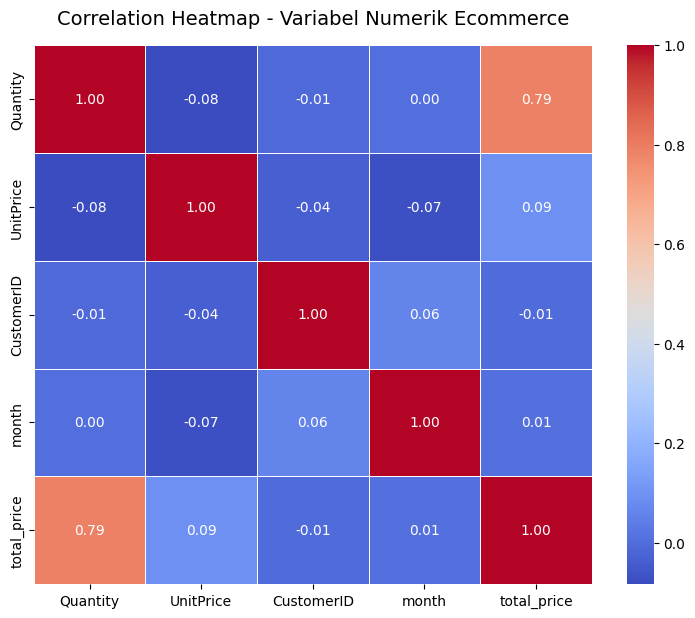

In [ ]:
# Analisis Multivariate
plt.figure(figsize=(9, 7))

numerical_cols = df[['Quantity', 'UnitPrice', 'CustomerID', 'month', 'total_price']]

sns.heatmap(numerical_cols.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap - Variabel Numerik Ecommerce', fontsize=14, pad=15)
plt.show()

**Insight:**

1. **Hubungan Quantity dan total_price (Korelasi Kuat: ~0.79):** Variabel Quantity (jumlah barang) memiliki nilai korelasi positif yang sangat kuat dan signifikan terhadap total_price (pendapatan). Hal ini membuktikan secara empiris bahwa kuantitas atau volume barang yang dibeli oleh pelanggan dalam setiap transaksi merupakan faktor pendorong utama (key driver) dalam peningkatan total omzet (revenue) perusahaan.

2. **Hubungan UnitPrice dan total_price (Korelasi Lemah: ~0.09):** Berbeda dengan kuantitas, harga satuan barang (UnitPrice) menunjukkan korelasi positif yang sangat lemah mendekati nol terhadap total_price. Ini mengindikasikan bahwa fluktuasi harga produk (apakah produk itu murah atau mahal) tidak terlalu memengaruhi total nilai transaksi pada dataset ini. Strategi bisnis e-commerce ini lebih bergantung pada volume penjualan (menjual barang dalam jumlah banyak) dibandingkan mengandalkan margin tinggi dari harga barang mahal.

3. **Hubungan CustomerID dan month terhadap Variabel Lain (Korelasi Mendekati 0):** Variabel CustomerID dan month tidak memiliki hubungan linear (korelasi berkisar antara -0.01 hingga 0.01) dengan variabel finansial seperti harga atau kuantitas. Hal ini wajar karena nomor identitas pelanggan dan urutan bulan bertindak sebagai variabel penanda/indeks waktu, sehingga tidak memengaruhi nilai transaksi secara linear.

# Exploratory Data Analysis

## Pertanyaan 1: Bagaimana tren penjualan (revenue) dari bulan ke bulan?

**Metode Pandas:** groupby(), agg(sum), working with datetime (month).

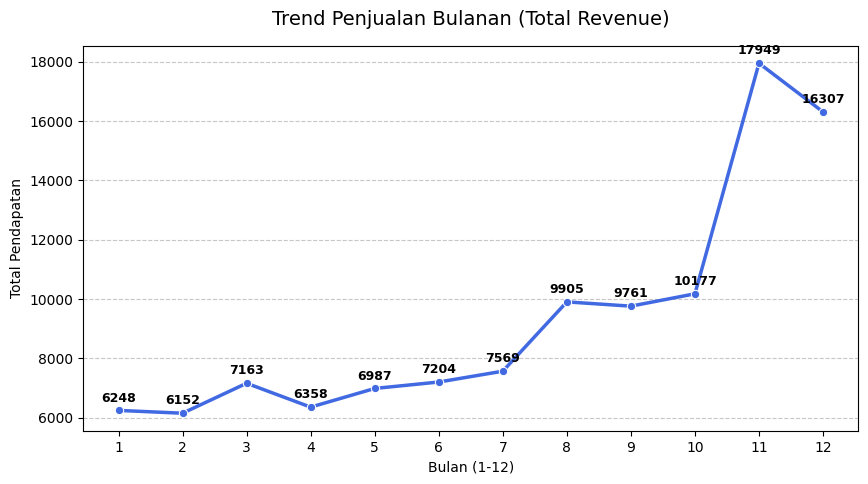

In [ ]:
# Manipulasi Data
monthly_sales = df.groupby('month')['total_price'].sum().reset_index()

# Visualisasi
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x='month', y='total_price', marker='o', color='royalblue', linewidth=2.5)

for i in range(len(monthly_sales)):
    plt.text(
        x=monthly_sales['month'][i],
        y=monthly_sales['total_price'][i] + 300, # '+ 300' memberikan jarak sedikit di atas titik agar tidak menempel
        s=f"{monthly_sales['total_price'][i]:.0f}", # Menampilkan angka bulat tanpa desimal
        ha='center', # Posisi teks rata tengah terhadap titik
        fontsize=9,
        weight='bold',
        color='black'
    )

plt.title('Trend Penjualan Bulanan (Total Revenue)', fontsize=14, pad=15)
plt.xlabel('Bulan (1-12)')
plt.ylabel('Total Pendapatan')
plt.xticks(range(1, 13))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Insight:**

Berdasarkan grafik line plot di atas, berikut adalah pola utama pendapatan perusahaan sepanjang tahun:

1. **Awal Tahun (Januari - April):** Penjualan cenderung stabil dan mendatar (flat) di kisaran angka 6.000 hingga 7.000.

2. **Pertengahan Tahun (Mei - Juli):** Mulai menunjukkan pertumbuhan bertahap hingga merangkak naik mendekati angka 8.000 pada bulan Juli.

3. **Lonjakan Pertama (Agustus):** Terjadi lompatan performa yang cukup masif hingga menembus angka sekitar 9.905.

4. **Puncak Penjualan (Oktober - Desember):** Memasuki akhir tahun, grafik melonjak sangat tajam (exponential growth). Bulan November dan Desember menjadi Peak Season (puncak tertinggi) yang melampaui batas atas grafik.

**Rekomendasi:**

1. **Antisipasi Akhir Tahun:** Mengingat tingginya permintaan di Q4 (efek holiday season), perusahaan harus mengamankan stok produk terlaris dan kapasitas logistik sejak bulan September agar tidak kehabisan barang.

2. **Strategi Periode Sepi:** Bulan Januari hingga April adalah masa sepi (low season). Tim marketing disarankan membuat program loyalitas atau promo khusus untuk mendongkrak kembali minat belanja pelanggan.

## Pertanyaan 2: Hari apa saja dalam seminggu yang mencatatkan jumlah transaksi unik terbanyak?

**Metode**: groupby(), nunique() pada InvoiceNo, reindex() menggunakan nama hari terurut.

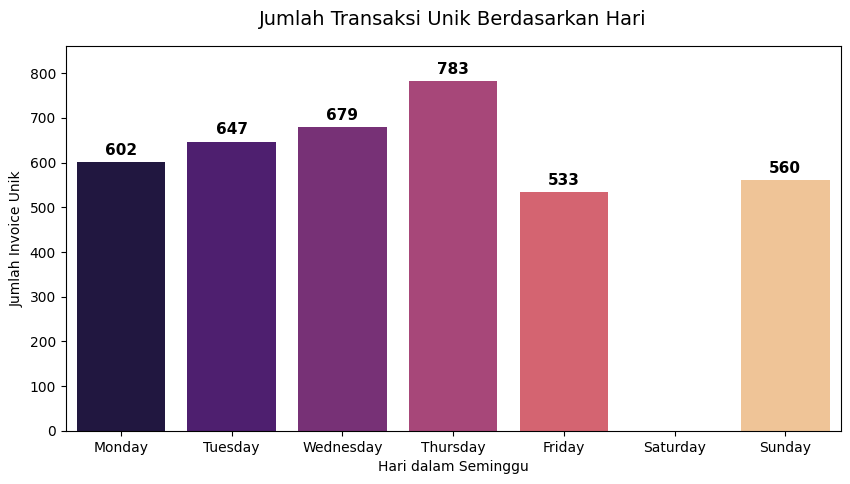

In [ ]:
# Manipulasi Data
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_orders = df.groupby('day_name')['InvoiceNo'].nunique().reindex(day_order).reset_index()

# Visualisasi
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=daily_orders, x='day_name', y='InvoiceNo', hue='day_name', palette='magma', legend=False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=11, weight='bold')

plt.title('Jumlah Transaksi Unik Berdasarkan Hari', fontsize=14, pad=15)
plt.xlabel('Hari dalam Seminggu')
plt.ylabel('Jumlah Invoice Unik')
plt.ylim(0, daily_orders['InvoiceNo'].max() * 1.1)
plt.show()

**Insight:**

Berdasarkan grafik batang (bar plot) di atas yang menampilkan metrik jumlah invoice unik, kita dapat mengidentifikasi pola perilaku belanja harian pelanggan:

1. **Puncak Aktivitas Bisnis (Peak Day):** Hari Kamis menduduki posisi tertinggi dengan total 785 transaksi, disusul oleh hari Rabu (679 transaksi) dan Selasa (646 transaksi). Ini mengindikasikan bahwa pertengahan minggu (mid-week) adalah waktu paling aktif bagi pelanggan untuk melakukan order.

2. **Penurunan Menjelang Akhir Pekan:** Jumlah transaksi mulai menyusut pada hari Jumat (533 transaksi) seiring berakhirnya hari kerja.

3. **Anomali Hari Sabtu:** Hari Sabtu mencatatkan 0 transaksi. Pola ini mengonfirmasi adanya kebijakan operasional platform e-commerce (misalnya sistem B2B/grosir) yang meliburkan pemrosesan pesanan atau operasional gudang di akhir pekan.

4. **Pemulihan di Hari Minggu:** Aktivitas belanja kembali bangkit (rebound) pada hari Minggu dengan mencatatkan 561 transaksi, menandakan pelanggan mulai mencicil pesanan untuk kebutuhan stok minggu baru.

**Rekomendasi:**

1. **Optimalisasi Waktu Kampanye (Campaign Timing):** Tim marketing sangat disarankan untuk meluncurkan program promo besar, kupon kilat (flash sale), atau mengirimkan newsletter iklan pada Rabu malam atau Kamis pagi guna memaksimalkan tingkat konversi (conversion rate) saat lalu lintas pembeli berada di titik tertinggi.

2. **Alokasi Tenaga Kerja Operasional:** Fokuskan jumlah staf pelayanan pelanggan (customer service) dan tim pengepakan gudang secara maksimal pada hari Selasa hingga Kamis untuk mengantisipasi lonjakan pemrosesan barang, sementara kapasitas tim dapat dikurangi secara efisien pada hari Jumat dan Sabtu.

## Pertanyaan 3: Negara (Country) mana saja yang menjadi Top 5 pasar terbesar berdasarkan kontribusi total revenue?

**Metode:** groupby(), sum(), sort_values(), head(5).

/tmp/ipykernel_1606/637003807.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_countries, x='total_price', y='Country', palette='viridis')


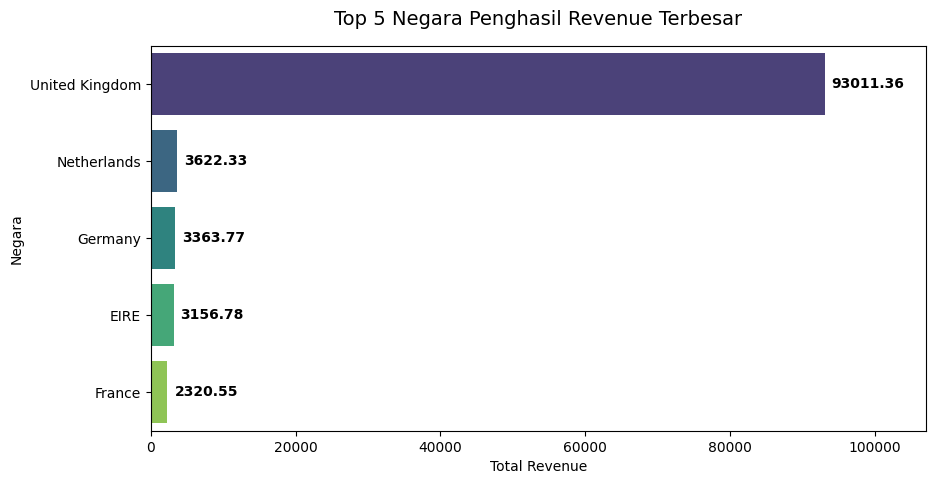

In [ ]:
# 1. Manipulasi Data
top_countries = df.groupby('Country')['total_price'].sum().sort_values(ascending=False).head(5).reset_index()

# 2. Visualisasi
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top_countries, x='total_price', y='Country', palette='viridis')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=5, fontsize=10, weight='bold')

plt.title('Top 5 Negara Penghasil Revenue Terbesar', fontsize=14, pad=15)
plt.xlabel('Total Revenue')
plt.ylabel('Negara')
plt.xlim(0, top_countries['total_price'].max() * 1.15)
plt.show()

**Insight:**

Berdasarkan grafik batang horizontal di atas, kontribusi pendapatan (revenue) perusahaan menunjukkan adanya dominasi geografis yang sangat kontras:

1. **Dominasi Mutlak Pasar Utama:** Negara United Kingdom (UK) merupakan pasar tunggal terbesar yang mendominasi seluruh pendapatan perusahaan secara absolut dengan total revenue mencapai 93.011,36. Nilai ini terpaut sangat jauh dan masif dibandingkan negara-negara lainnya.

2. **Pasar Sekunder Eropa:** Posisi kedua hingga kelima ditempati oleh negara-negara Eropa lainnya, yaitu Germany (3.230,13), EIRE/Irlandia (2.560,32), France (2.282,15), dan Netherlands (1.378,60). Meskipun angka penjualan mereka jauh di bawah UK, keempat negara ini merupakan representasi pasar internasional utama bagi perusahaan.

**Rekomendasi:**

1. **Proteksi & Retensi Pasar Utama (UK):** Mengingat UK adalah tulang punggung (backbone) bisnis perusahaan, efisiensi rantai pasok (supply chain), ketersediaan stok di gudang lokal, dan kepuasan pelanggan di area ini harus menjadi prioritas nomor satu. Gangguan operasional kecil di UK akan berdampak fatal pada kestabilan total pendapatan global perusahaan.

2. **Strategi Penetrasi Pasar Internasional:** Jangan bergantung hanya pada satu negara. Tim marketing dan ekspansi bisnis disarankan untuk mempelajari karakteristik produk populer di Germany dan EIRE, lalu mereplikasi taktik promosi yang sukses di UK dengan penyesuaian lokal (lokalisasi kampanye iklan) guna menumbuhkan kontribusi revenue dari pasar internasional tersebut.

## Pertanyaan 4: Apa saja 5 produk (Description) yang paling laris dan tidak laris terjual secara kuantitas?

**Metode:** Grouping, Aggregation, Sorting

/tmp/ipykernel_1606/3171472428.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_products, x='Quantity', y='Description', palette='flare')


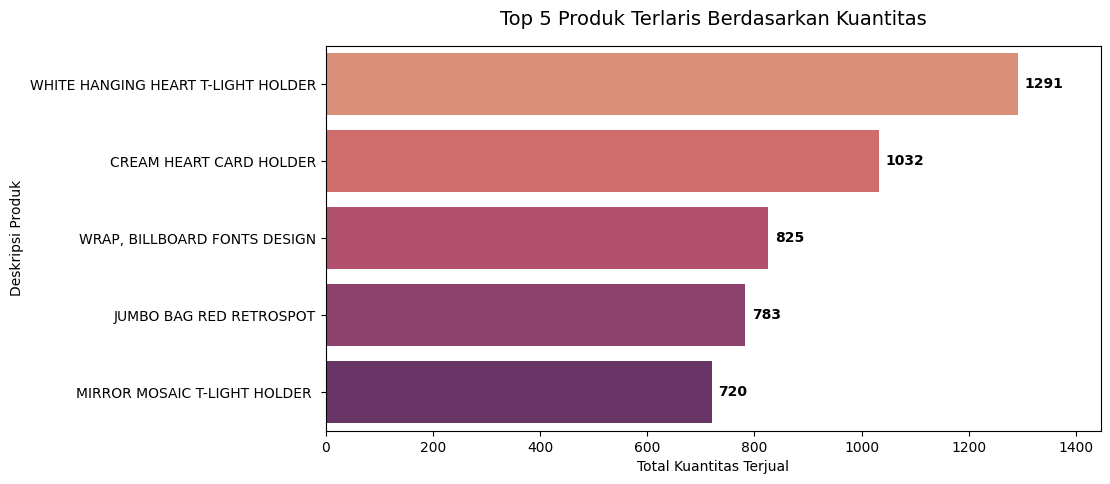

In [ ]:
# Manipulasi Data
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5).reset_index()

# Visualisasi
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top_products, x='Quantity', y='Description', palette='flare')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=5, fontsize=10, weight='bold')

plt.title('Top 5 Produk Terlaris Berdasarkan Kuantitas', fontsize=14, pad=15)
plt.xlabel('Total Kuantitas Terjual')
plt.ylabel('Deskripsi Produk')
plt.xlim(0, top_products['Quantity'].max() * 1.12)
plt.show()

**Insight:**

Berdasarkan grafik bar plot di atas, kita dapat mengidentifikasi performa produk best-seller perusahaan:

1. **Produk Unggulan Utama:** WHITE HANGING HEART T-LIGHT HOLDER mendominasi pasar sebagai produk paling laris dengan total kuantitas penjualan tertinggi (menembus angka hampir 1.300 unit).

2. **Produk Kompetitif Kedua:** CREAM HEART CARD HOLDER menyusul di posisi kedua dengan performa yang cukup kuat (di atas 1.000 unit).

3. **Kelompok Produk Pelengkap:** Tiga produk berikutnya (WRAP, BILLBOARD FONTS DESIGN, JUMBO BAG RED RETROSPOT, dan MIRROR MOSAIC T-LIGHT HOLDER) memiliki tren penjualan yang kompetitif dan stabil di kisaran 700 hingga 800 unit.

**Rekomendasi:**

1. **Manajemen Inventaris Ketat (Anti Stock-Out):** Kelima produk ini adalah pendorong utama volume penjualan perusahaan. Pastikan ketersediaan stok (safety stock) untuk kelima item ini selalu terjaga di gudang, terutama menjelang kuartal keempat (peak season).

2. **Strategi Product Bundling:** Manfaatkan popularitas produk teratas (seperti dekorasi bertema Heart/T-Light) untuk mendongkrak penjualan produk yang kurang populer dengan cara membuat paket bundling (misalnya: beli produk best-seller gratis/diskon produk pelengkap).

## Pertanyaan 5: Siapa saja 5 pelanggan (CustomerID) paling loyal dengan total pengeluaran terbesar?

**Metode:** groupby(), sum(), sort_values(), head(5), astype string untuk kebutuhan plotting.

/tmp/ipykernel_1606/219766161.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_customers, x='CustomerID', y='total_price', palette='magma')


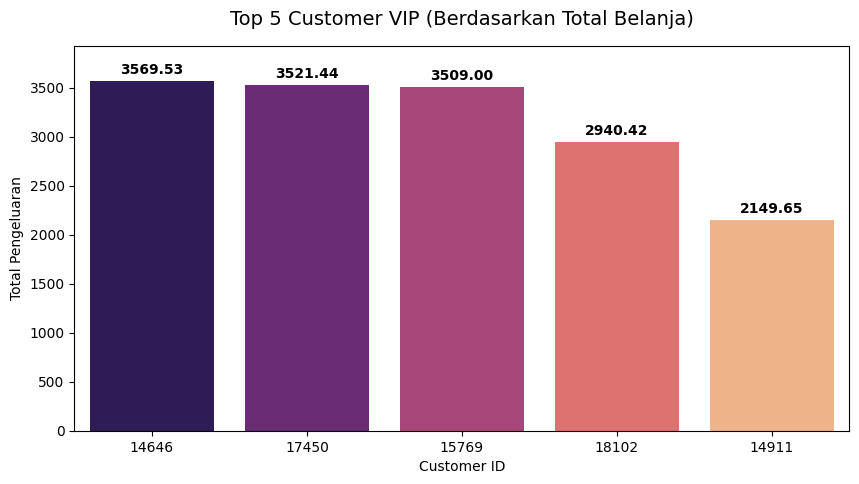

In [ ]:
# Manipulasi Data
top_customers = df.groupby('CustomerID')['total_price'].sum().sort_values(ascending=False).head(5).reset_index()
top_customers['CustomerID'] = top_customers['CustomerID'].astype(str) # Ubah ke string agar rapi di sumbu X

# Visualisasi
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top_customers, x='CustomerID', y='total_price', palette='magma')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=10, weight='bold')

plt.title('Top 5 Customer VIP (Berdasarkan Total Belanja)', fontsize=14, pad=15)
plt.xlabel('Customer ID')
plt.ylabel('Total Pengeluaran')
plt.ylim(0, top_customers['total_price'].max() * 1.1)
plt.show()

**Insight:**

Berdasarkan grafik batang (bar plot) di atas, kita dapat menganalisis profil pengeluaran dari kelompok pelanggan kontributor tertinggi (top-tier spenders) perusahaan:

1. **Persaingan Ketat Kelompok Tiga Besar:** Pelanggan dengan ID 14646 (3.569,53), 17450 (3.521,44), dan 15769 (3.509,00) memiliki akumulasi nilai belanja yang sangat kompetitif dan hanya terpaut tipis satu sama lain. Ketiganya merupakan pilar utama dalam kelompok pelanggan VIP.

2. **Kelompok VIP Sekunder:** Posisi keempat dan kelima ditempati oleh pelanggan 18102 (2.940,42) dan 14911 (2.149,65). Meskipun nilai belanjanya berada di bawah kelompok tiga besar, kontribusi finansial mereka tetap jauh melampaui rata-rata pengeluaran pelanggan umum pada dataset ini.

**Rekomendasi:**

1. **Program Retensi Khusus (VIP Loyalty Program):** Mengingat kelima pelanggan ini memiliki nilai Customer Lifetime Value (CLV) yang sangat tinggi, perusahaan wajib memberikan perlakuan khusus seperti akses awal ke produk baru, manajer akun pribadi (dedicated account manager), atau layanan pengiriman prioritas tanpa biaya tambahan guna mengunci loyalitas mereka.

2. **Apresiasi dan Strategi Upselling:** Kirimkan program apresiasi terpersonalisasi (misalnya insentif berbasis kuota volume belanja) khusus untuk pelanggan 18102 dan 14911 guna mendorong mereka meningkatkan frekuensi atau volume transaksi agar bisa menyamai tingkat pengeluaran kelompok tiga besar.